# Process B — Batch Classification

## Problem

| Metric | Value |
|---|---|
| Total calibration batches | **40** |
| Accepted | 35 (87.5%) |
| **Rejected** | **5 (12.5%)** |
| Imbalance ratio | **7:1** |
| Time steps per batch | 5,001 (fixed) |
| Sensor features | 20 |
| Test batches | 40 |

## Key Insights from EDA

- **All 5 rejected batches** show the same sharp `aeration_rate` dip in the **10–25% time window** (time steps 500–1250, −1.5 to −2.3 below the batch's own level). Accepted batches have flat aeration.
- Accepted batches run at very **different aeration set-points (4.8 to 8.1)**. **B_032** looks different only because its set-point is low (about 5.1). Accepted **B_044** is even lower (4.8), so a low level is *not* a fault. Relative to its own baseline, B_032 has exactly the same dip (§2.3–2.4).
- **Modelling consequence:** look at deviations relative to each batch's own level (shape), not absolute levels. This is what makes a model robust to unseen but acceptable set-points.
- In accepted batches, 9 features are nearly constant (std < 0.01): `ph`, `reactor_temperature`, `aeration_rate`, `hot_cold_switch`, etc.
- The rejection signal is **local** (brief event), not global — so time-resolved features (time bins, ranges) are needed.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
sns.set_palette('Set2')
%matplotlib inline

In [2]:
# Locate the data: $BRPMM_DATA, any parent folder containing input-data/, or the Renku default
import os
def find_data():
    if os.environ.get('BRPMM_DATA'):
        return Path(os.environ['BRPMM_DATA'])
    for parent in [Path.cwd(), *Path.cwd().parents]:
        cand = parent / 'input-data' / 'Project 2 - BRPMM'
        if cand.is_dir():
            return cand
    return Path('/home/renku/work/input-data/Project 2 - BRPMM')

BASE = find_data()
CALIB_DATA = BASE / 'process B' / 'calibration data' / 'calibration_data.csv'
CALIB_LABELS = BASE / 'process B' / 'calibration data' / 'calibration_labels.csv'
TEST_DATA = BASE / 'process B' / 'test data' / 'test_data.csv'
TEMPLATE = BASE / 'BRPMM_template.csv'

print('Data folder:', BASE)

Data folder: /Users/ramonamaj/zurich jj/input-data/Project 2 - BRPMM


In [3]:
# Load data
df_calib = pd.read_csv(CALIB_DATA)
df_labels = pd.read_csv(CALIB_LABELS)
df_test = pd.read_csv(TEST_DATA)
df_template = pd.read_csv(TEMPLATE, dtype={'batch_id': str})

feat_cols = [c for c in df_calib.columns if c != 'batch_id']

print(f'Calibration data: {df_calib.shape}')
print(f'Labels:           {df_labels.shape}')
print(f'Test data:        {df_test.shape}')
print(f'Features ({len(feat_cols)}): {feat_cols}')

# Label distribution
label_counts = df_labels['label'].value_counts()
print(f'\nLabel distribution:')
for label, count in label_counts.items():
    print(f'  {label}: {count} ({count/len(df_labels)*100:.1f}%)')

rejected_ids = df_labels[df_labels['label'] == 'rejected']['batch_id'].tolist()
accepted_ids = df_labels[df_labels['label'] == 'accepted']['batch_id'].tolist()
print(f'\nRejected batches: {rejected_ids}')
print(f'Accepted batches: {len(accepted_ids)} total')

Calibration data: (200040, 21)
Labels:           (40, 2)
Test data:        (200040, 21)
Features (20): ['substrate_concentration', 'dissolved_oxygen', 'biomass_concentration', 'penicillin_concentration', 'fermentation_volume', 'dissolved_co2', 'ph', 'reactor_temperature', 'reaction_heat', 'feed_rate', 'aeration_rate', 'agitator_power', 'feed_temperature', 'water_flow_rate', 'hot_cold_switch', 'base_flow', 'acid_flow', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']

Label distribution:
  accepted: 35 (87.5%)
  rejected: 5 (12.5%)

Rejected batches: ['B_017', 'B_032', 'B_049', 'B_075', 'B_078']
Accepted batches: 35 total


---
## 1. Samples per Batch

Every batch has exactly **5,001 time steps** — both calibration and test. This is fixed-length data, which simplifies window-based modeling.

In [4]:
# Calibration data — samples per batch
batch_samples = df_calib.groupby('batch_id').size()

print(f'Batch time steps: min={batch_samples.min()}, max={batch_samples.max()}, '
      f'mean={batch_samples.mean():.0f}, std={batch_samples.std():.0f}')

# Show all batches with their labels and time step counts
batch_info = batch_samples.reset_index(name='n_samples').merge(df_labels, on='batch_id')
print(f'\nAll 40 calibration batches:')
print(f'{"Batch":<8s} {"Label":<10s} {"Samples":>8s}')
print('-' * 30)
for _, row in batch_info.sort_values('batch_id').iterrows():
    marker = ' ⬅ REJECTED' if row['label'] == 'rejected' else ''
    print(f'{row["batch_id"]:<8s} {row["label"]:<10s} {row["n_samples"]:>8d}{marker}')

# Test data — samples per batch
test_samples = df_test.groupby('batch_id').size()
print(f'\n\nTest batches: {len(test_samples)}, all with {test_samples.iloc[0]} time steps each')
print('\nAll 40 test batches:')
for bid in sorted(test_samples.index):
    print(f'  {bid}', end='')
print()

Batch time steps: min=5001, max=5001, mean=5001, std=0

All 40 calibration batches:
Batch    Label       Samples
------------------------------
B_001    accepted       5001
B_005    accepted       5001
B_006    accepted       5001
B_009    accepted       5001
B_011    accepted       5001
B_012    accepted       5001
B_014    accepted       5001
B_015    accepted       5001
B_017    rejected       5001 ⬅ REJECTED
B_019    accepted       5001
B_021    accepted       5001
B_022    accepted       5001
B_025    accepted       5001
B_028    accepted       5001
B_031    accepted       5001
B_032    rejected       5001 ⬅ REJECTED
B_034    accepted       5001
B_035    accepted       5001
B_037    accepted       5001
B_038    accepted       5001
B_039    accepted       5001
B_043    accepted       5001
B_044    accepted       5001
B_045    accepted       5001
B_047    accepted       5001
B_049    rejected       5001 ⬅ REJECTED
B_050    accepted       5001
B_051    accepted       5001
B_053    ac

---
## 2. Exploratory Data Analysis

### 2.1 Key Feature: `aeration_rate` — The Main Signal

All 5 rejected batches show a sharp dip in the 10–25% window. B_032's dip starts from a lower set-point, which is why it can look "always low" on an absolute scale.

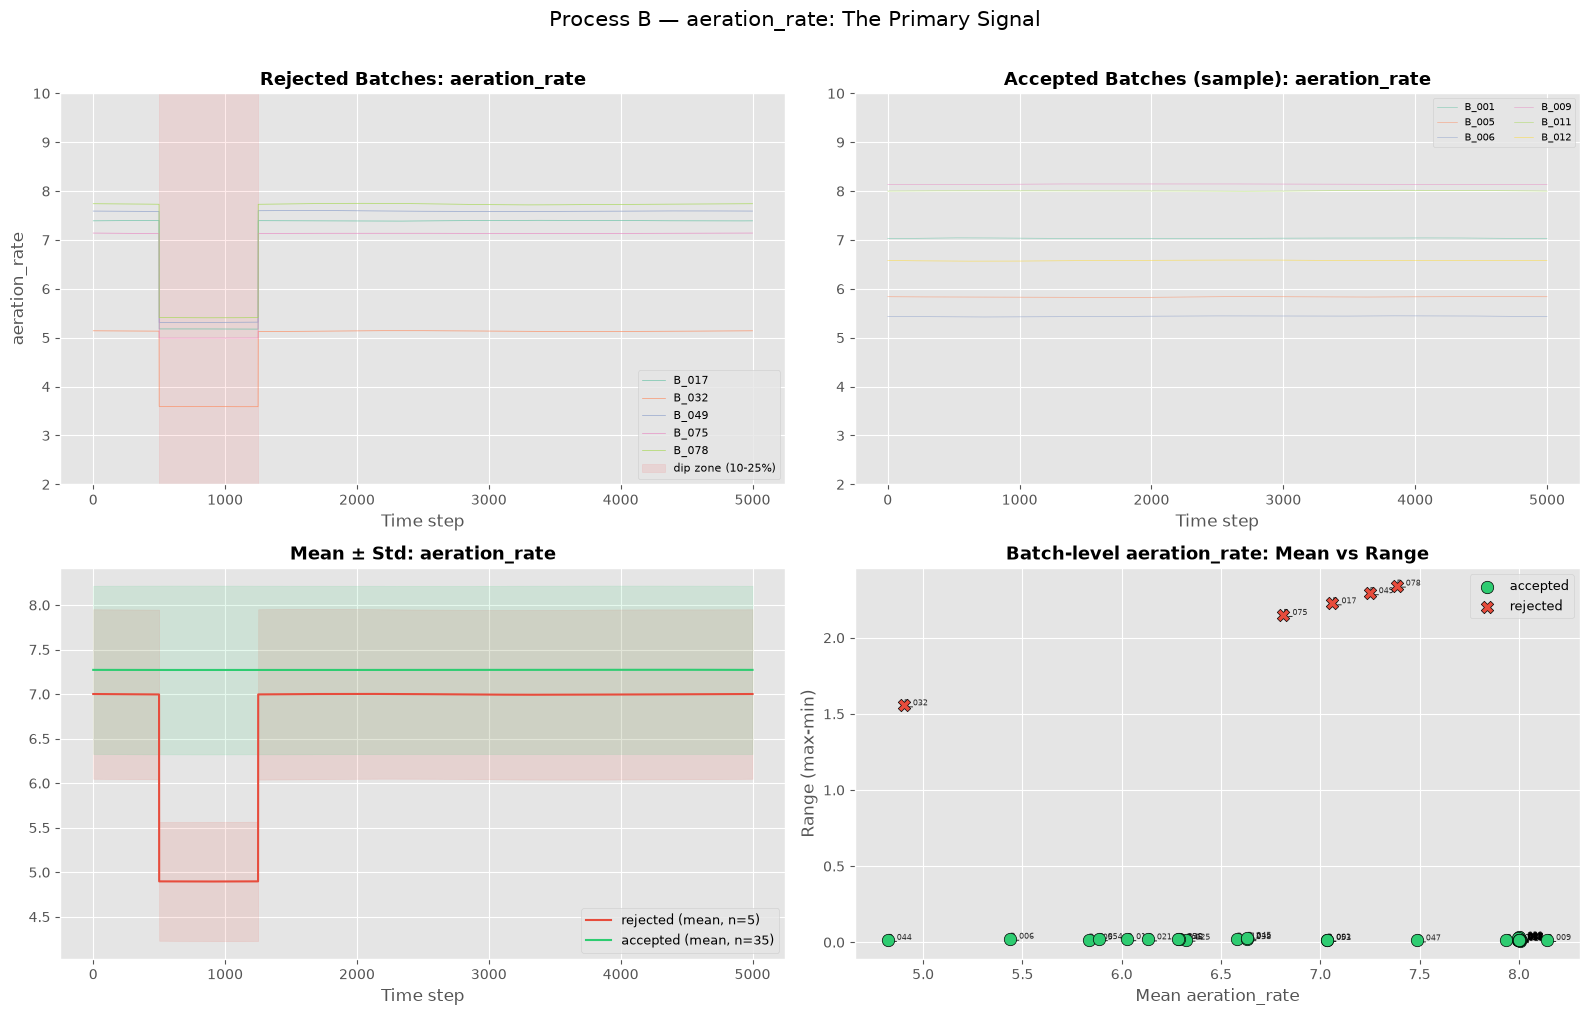

In [5]:
# Merge labels for plotting
df_labeled = df_calib.merge(df_labels, on='batch_id')

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plot 1: All 5 rejected — aeration_rate
ax = axes[0, 0]
for bid in rejected_ids:
    sub = df_labeled[df_labeled['batch_id'] == bid]
    ax.plot(sub['aeration_rate'].values, linewidth=0.5, label=bid, alpha=0.9)
ax.axvspan(500, 1250, alpha=0.08, color='red', label='dip zone (10-25%)')
ax.set_title('Rejected Batches: aeration_rate', fontsize=13, fontweight='bold')
ax.set_xlabel('Time step'); ax.set_ylabel('aeration_rate')
ax.legend(fontsize=8); ax.set_ylim(2, 10)

# Plot 2: Sample of accepted — aeration_rate
ax = axes[0, 1]
for bid in accepted_ids[:6]:
    sub = df_labeled[df_labeled['batch_id'] == bid]
    ax.plot(sub['aeration_rate'].values, linewidth=0.4, label=bid, alpha=0.8)
ax.set_title('Accepted Batches (sample): aeration_rate', fontsize=13, fontweight='bold')
ax.set_xlabel('Time step'); ax.legend(fontsize=7, ncol=2); ax.set_ylim(2, 10)

# Plot 3: Mean ± std comparison
ax = axes[1, 0]
colors = {'rejected': '#e74c3c', 'accepted': '#2ecc71'}
for label, ids in [('rejected', rejected_ids), ('accepted', accepted_ids)]:
    stacked = np.vstack([df_labeled[df_labeled['batch_id'] == bid]['aeration_rate'].values for bid in ids])
    mean = stacked.mean(axis=0)
    std = stacked.std(axis=0)
    ax.plot(mean, color=colors[label], linewidth=1.5, label=f'{label} (mean, n={len(ids)})')
    ax.fill_between(range(len(mean)), mean - std, mean + std, color=colors[label], alpha=0.12)
ax.set_title('Mean ± Std: aeration_rate', fontsize=13, fontweight='bold')
ax.set_xlabel('Time step'); ax.legend(fontsize=9)

# Plot 4: Per-batch aeration_rate statistics
ax = axes[1, 1]
stats = []
for bid in sorted(df_labels['batch_id'].unique()):
    vals = df_labeled[df_labeled['batch_id'] == bid]['aeration_rate'].values
    label = df_labels[df_labels['batch_id'] == bid]['label'].iloc[0]
    stats.append({
        'batch_id': bid, 'label': label,
        'mean': vals.mean(), 'std': vals.std(),
        'min': vals.min(), 'max': vals.max(),
        'range': vals.max() - vals.min()
    })
df_stats = pd.DataFrame(stats)

for label, marker, color in [('accepted', 'o', '#2ecc71'), ('rejected', 'X', '#e74c3c')]:
    subset = df_stats[df_stats['label'] == label]
    ax.scatter(subset['mean'], subset['range'], marker=marker, c=color, s=80,
               label=label, edgecolors='black', linewidth=0.5, zorder=5)
    for _, row in subset.iterrows():
        ax.annotate(row['batch_id'], (row['mean'], row['range']), fontsize=6, alpha=0.8)
ax.set_xlabel('Mean aeration_rate'); ax.set_ylabel('Range (max-min)')
ax.set_title('Batch-level aeration_rate: Mean vs Range', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)

plt.suptitle('Process B — aeration_rate: The Primary Signal', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

In [6]:
# Detailed stats for every batch
print('Per-batch aeration_rate statistics:')
print(df_stats.to_string(index=False))

Per-batch aeration_rate statistics:
batch_id    label     mean      std      min      max    range
   B_001 accepted 7.034816 0.005340 7.025199 7.042210 0.017011
   B_005 accepted 5.833635 0.005054 5.823190 5.840729 0.017539
   B_006 accepted 5.437653 0.007433 5.423999 5.447029 0.023030
   B_009 accepted 8.141287 0.004657 8.133558 8.148488 0.014931
   B_011 accepted 8.005805 0.005824 7.997509 8.017960 0.020451
   B_012 accepted 6.579014 0.006703 6.566233 6.590002 0.023769
   B_014 accepted 6.026944 0.005612 6.019314 6.039867 0.020553
   B_015 accepted 7.997323 0.003805 7.991245 8.005085 0.013840
   B_017 rejected 7.060992 0.791403 5.176062 7.402219 2.226157
   B_019 accepted 8.004031 0.001869 8.000000 8.007862 0.007862
   B_021 accepted 6.131600 0.005013 6.121241 6.140054 0.018813
   B_022 accepted 8.001311 0.006481 7.988800 8.014032 0.025232
   B_025 accepted 6.325050 0.004978 6.316479 6.333557 0.017078
   B_028 accepted 7.998386 0.006428 7.986288 8.008627 0.022340
   B_031 accepted 7

### 2.2 Other Important Features: First 500 Steps

Zoom into the critical time window to see what happens during the aeration dip.

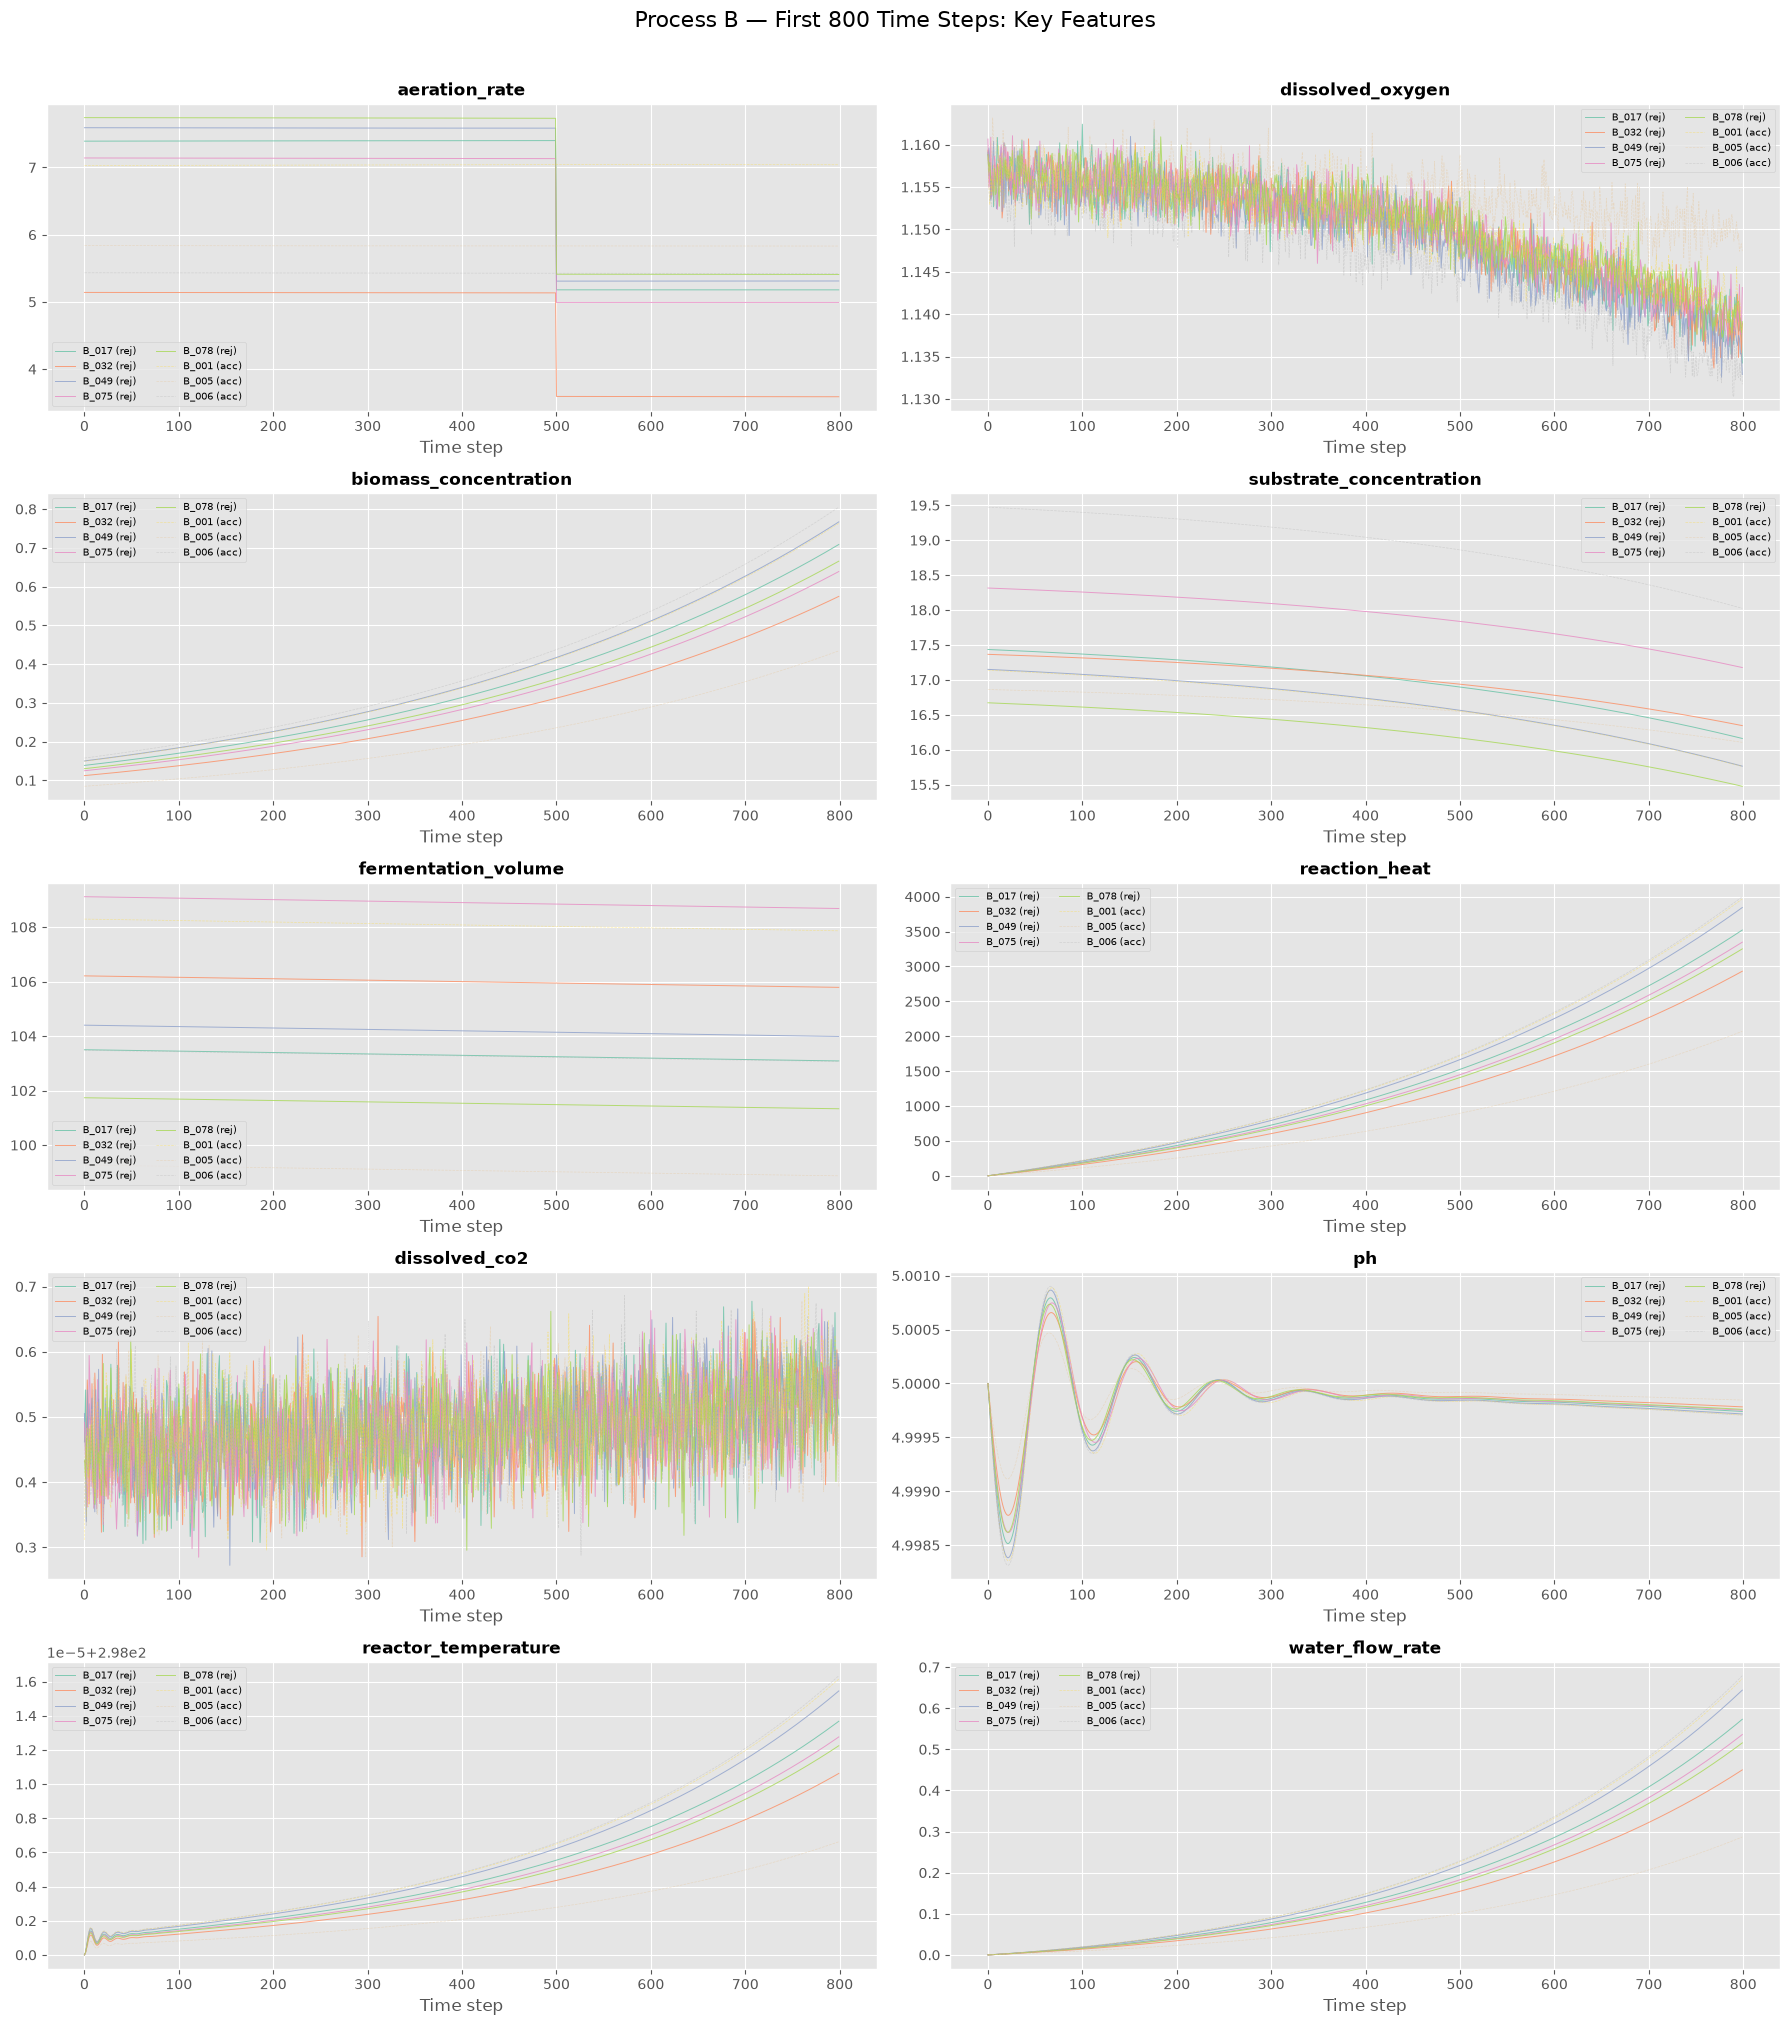

In [7]:
key_feats = ['aeration_rate', 'dissolved_oxygen', 'biomass_concentration',
             'substrate_concentration', 'fermentation_volume', 'reaction_heat',
             'dissolved_co2', 'ph', 'reactor_temperature', 'water_flow_rate']

fig, axes = plt.subplots(5, 2, figsize=(18, 20))
axes = axes.flatten()
zoom = 800  # first 800 time steps

for i, feat in enumerate(key_feats):
    ax = axes[i]
    for bid in rejected_ids:
        sub = df_labeled[df_labeled['batch_id'] == bid]
        ax.plot(sub[feat].values[:zoom], linewidth=0.7, label=f'{bid} (rej)', alpha=0.8)
    # Sample 3 accepted for reference
    for bid in accepted_ids[:3]:
        sub = df_labeled[df_labeled['batch_id'] == bid]
        ax.plot(sub[feat].values[:zoom], linewidth=0.5, label=f'{bid} (acc)', alpha=0.4, linestyle='--')
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.set_xlabel('Time step')
    ax.legend(fontsize=7, ncol=2, loc='best')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Process B — First 800 Time Steps: Key Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 2.3 All 5 Rejected vs Accepted: Deep Comparison

On an absolute scale B_032 looks like the odd one out: its aeration_rate mean is 4.90 against an accepted mean of 7.27. But accepted batches themselves run at set-points from **4.8 (B_044)** to **8.1**, so a low level alone is normal.

The plot below removes each batch's own baseline (its median aeration_rate). Relative to its baseline, **B_032 has exactly the same dip as the other four rejected batches**, at the same time steps (500–1250) with a similar depth (−1.5, against −2.1 to −2.3 for the others).

**One rejection pattern, not two:** a transient aeration drop at 10–25% of the batch, superimposed on whatever set-point the batch runs at.

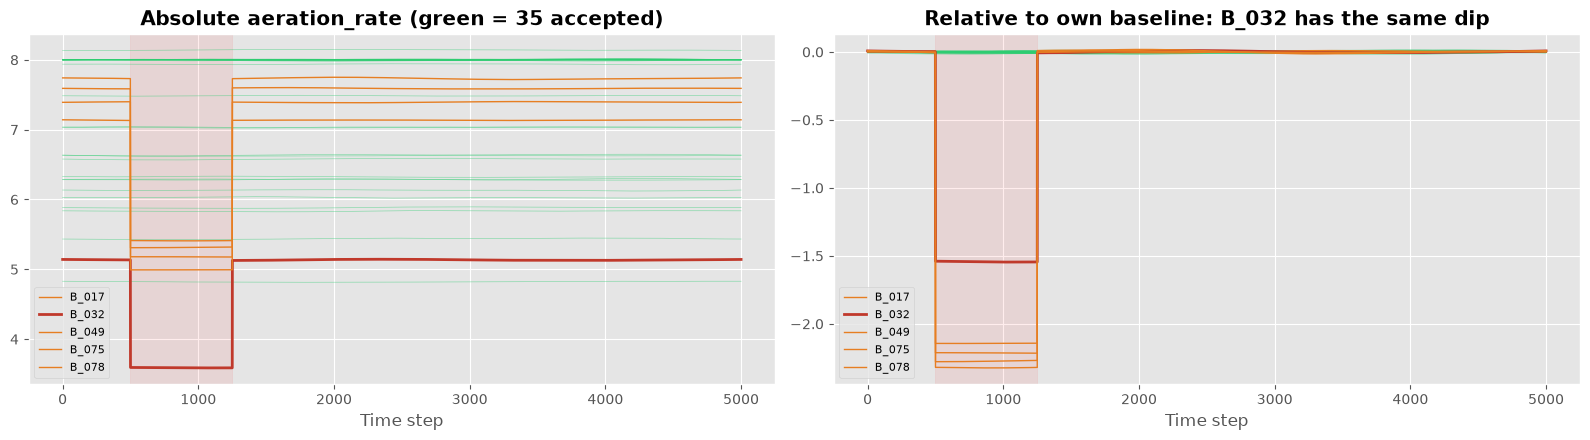

Dip depth (mean in steps 500-1250 minus batch median):
  B_017 (rejected) baseline  7.39  dip -2.21
  B_032 (rejected) baseline  5.13  dip -1.54
  B_049 (rejected) baseline  7.59  dip -2.27
  B_075 (rejected) baseline  7.14  dip -2.14
  B_078 (rejected) baseline  7.73  dip -2.32
  B_044 (accepted) baseline  4.82  dip -0.00
  B_006 (accepted) baseline  5.44  dip -0.01


In [8]:
# Aeration relative to each batch's own baseline (median) -> set-point removed
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for bid in accepted_ids:
    a = df_labeled.loc[df_labeled.batch_id == bid, 'aeration_rate'].values
    axes[0].plot(a, color='#2ecc71', lw=.5, alpha=.5)
    axes[1].plot(a - np.median(a), color='#2ecc71', lw=.5, alpha=.5)
for bid in rejected_ids:
    a = df_labeled.loc[df_labeled.batch_id == bid, 'aeration_rate'].values
    lw, c = (2, '#c0392b') if bid == 'B_032' else (1, '#e67e22')
    axes[0].plot(a, color=c, lw=lw, label=bid)
    axes[1].plot(a - np.median(a), color=c, lw=lw, label=bid)
axes[0].set_title('Absolute aeration_rate (green = 35 accepted)', fontweight='bold')
axes[1].set_title('Relative to own baseline: B_032 has the same dip', fontweight='bold')
for ax in axes:
    ax.axvspan(500, 1250, color='red', alpha=.07); ax.set_xlabel('Time step'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Dip depth (mean in steps 500-1250 minus batch median):')
for bid in rejected_ids + ['B_044', 'B_006']:
    a = df_labeled.loc[df_labeled.batch_id == bid, 'aeration_rate'].values
    lab_ = df_labels.set_index('batch_id').loc[bid, 'label']
    print(f'  {bid} ({lab_:8s}) baseline {np.median(a):5.2f}  dip {a[500:1250].mean() - np.median(a):+.2f}')

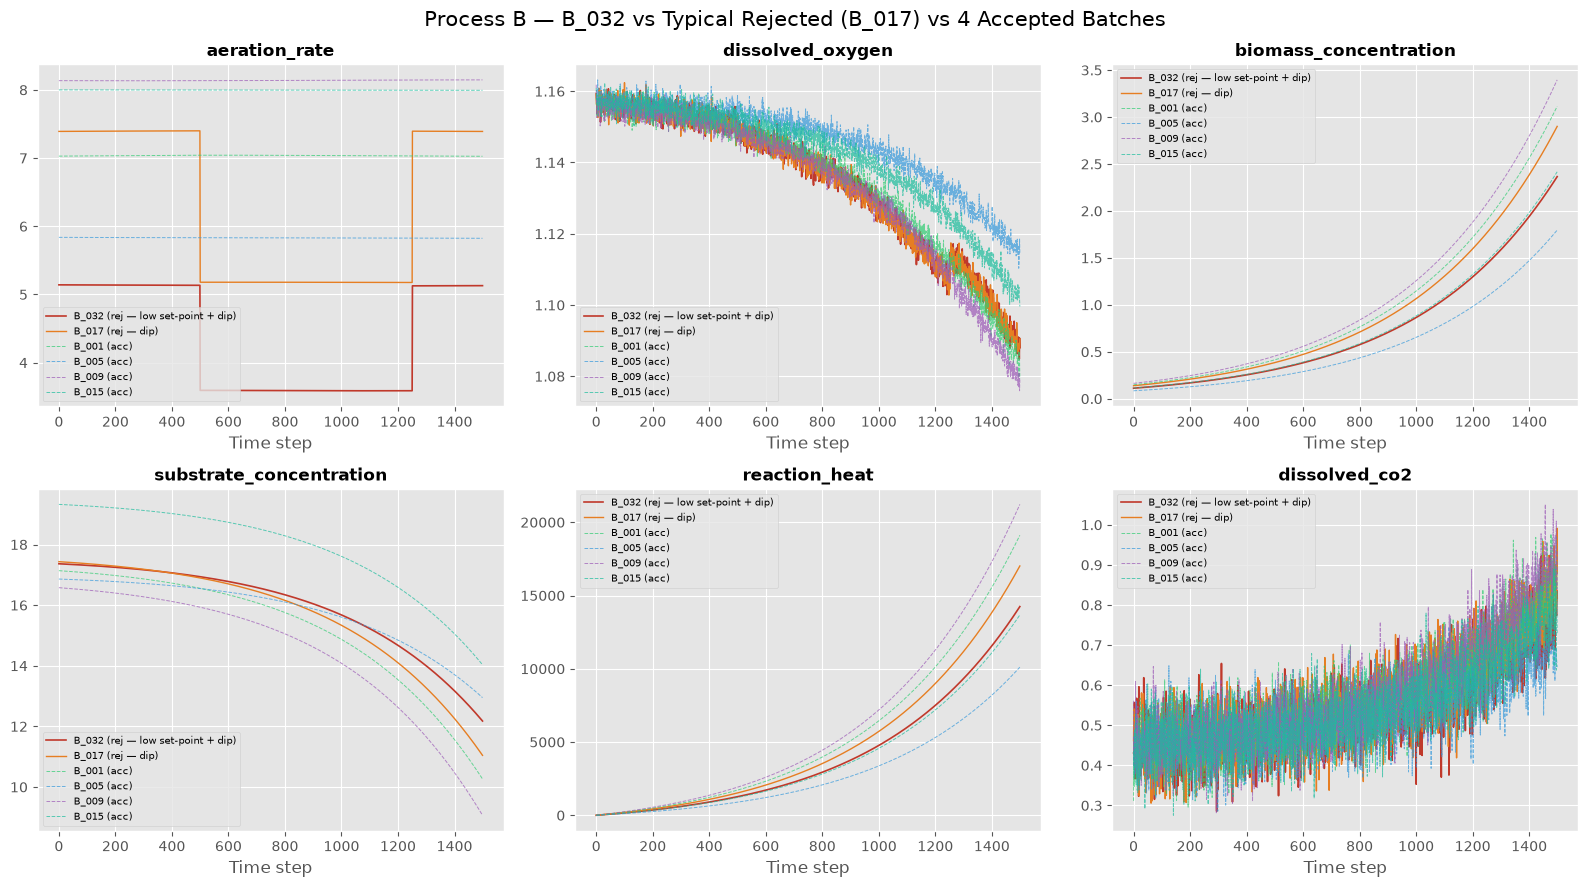

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

compare_feats = ['aeration_rate', 'dissolved_oxygen', 'biomass_concentration',
                 'substrate_concentration', 'reaction_heat', 'dissolved_co2']

for i, feat in enumerate(compare_feats):
    ax = axes[i // 3, i % 3]
    
    # B_032 — the special rejected (always low)
    sub = df_labeled[df_labeled['batch_id'] == 'B_032']
    ax.plot(sub[feat].values[:1500], linewidth=1.2, label='B_032 (rej — low set-point + dip)', color='#c0392b')
    
    # B_017 — typical dip-type rejected
    sub = df_labeled[df_labeled['batch_id'] == 'B_017']
    ax.plot(sub[feat].values[:1500], linewidth=1.0, label='B_017 (rej — dip)', color='#e67e22')
    
    # B_001, B_005, B_009, B_015 — accepted batches
    accepted_sample = ['B_001', 'B_005', 'B_009', 'B_015']
    acc_colors = ['#2ecc71', '#3498db', '#9b59b6', '#1abc9c']
    for bid_acc, clr in zip(accepted_sample, acc_colors):
        sub = df_labeled[df_labeled['batch_id'] == bid_acc]
        ax.plot(sub[feat].values[:1500], linewidth=0.7, label=f'{bid_acc} (acc)',
                color=clr, linestyle='--', alpha=0.7)
    
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.set_xlabel('Time step'); ax.legend(fontsize=7, loc='best')

plt.suptitle('Process B — B_032 vs Typical Rejected (B_017) vs 4 Accepted Batches', fontsize=15)
plt.tight_layout()
plt.show()

### 2.4 B_032: low set-point plus the same dip

| Metric | B_032 | Other rejected (mean) | Accepted (mean) |
|---|---|---|---|
| aeration_rate mean | 4.90 | 7.13 | 7.27 (range of batch means 4.82–8.14) |
| aeration_rate baseline (start/end) | 5.14 | 7.47 | ≈ set-point |
| aeration_rate in steps 500–1250 | **3.59** (dip of −1.55) | dip of −2.1 to −2.3 | flat |
| aeration_rate range | 1.56 | 2.07 | 0.02 |
| dissolved_oxygen mean | 1.097 | 1.106 | 1.107 |
| biomass_concentration mean | 6.41 | 6.67 | 6.62 |

**Key insight:** B_032 is rejected for the **same reason** as the other four, the aeration dip. Its low mean is a coincidence of a low set-point, which also occurs in accepted batches (B_044 at 4.82, B_006 at 5.44).

**Implications for modelling**
- A model that relied on the *absolute* aeration level would wrongly reject a low-set-point accepted batch, or accept a high-set-point batch with a dip. Features must capture **shape relative to the batch's own level** (range, or centred trajectories).
- `aeration_rate_range` alone separates all 40 calibration batches (rejected ≥ 1.56, accepted ≤ 0.03).

In [10]:
# Quantify: how does B_032 compare to accepted batches on ALL features?
accepted_data = df_labeled[df_labeled['label'] == 'accepted']
b032_data = df_labeled[df_labeled['batch_id'] == 'B_032']
other_rej_data = df_labeled[df_labeled['batch_id'].isin([b for b in rejected_ids if b != 'B_032'])]

print(f'{"Feature":<35s} {"B_032":>8s} {"Other Rej":>10s} {"Accepted":>10s} {"B_032 vs Acc":>12s}')
print('-' * 80)

for feat in feat_cols:
    b032_mean = b032_data[feat].mean()
    other_mean = other_rej_data[feat].mean()
    acc_mean = accepted_data[feat].mean()
    diff_pct = ((b032_mean - acc_mean) / acc_mean * 100) if acc_mean != 0 else 0
    
    # Highlight features where B_032 deviates significantly
    marker = ' ⬅' if abs(diff_pct) > 5 else ''
    print(f'{feat:<35s} {b032_mean:>8.3f} {other_mean:>10.3f} {acc_mean:>10.3f} {diff_pct:>+11.1f}%{marker}')

print('\n→ On batch means, only aeration_rate differs strongly (-32.6%), and that is the low set-point:')
acc_means = accepted_data.groupby('batch_id')['aeration_rate'].mean()
print(f'  accepted batch means range {acc_means.min():.2f}–{acc_means.max():.2f} (B_032: {b032_data.aeration_rate.mean():.2f})')
print('→ All other features are within ~3% of the accepted mean')
print('→ So batch means cannot explain the rejection; the time-resolved dip (§2.3) does')

Feature                                B_032  Other Rej   Accepted B_032 vs Acc
--------------------------------------------------------------------------------
substrate_concentration                5.747      5.463      5.653        +1.7%
dissolved_oxygen                       1.097      1.106      1.107        -1.0%
biomass_concentration                  6.407      6.668      6.622        -3.2%
penicillin_concentration               0.169      0.178      0.174        -3.2%
fermentation_volume                  105.863    104.422    103.495        +2.3%
dissolved_co2                          1.356      1.388      1.382        -1.9%
ph                                     5.000      5.000      5.000        -0.0%
reactor_temperature                  298.000    298.000    298.000        +0.0%
reaction_heat                       40039.170  40995.465  40380.677        -0.8%
feed_rate                              0.034      0.035      0.035        -1.5%
aeration_rate                         

---
## 3. Feature Importance by Time Window

Which features matter most — and **when**? We compute per-window Random Forest importance.

In [11]:
from sklearn.ensemble import RandomForestClassifier

def feature_importance_by_window(df, labels_df, feature_cols, n_bins=10, top_k=5):
    """RF feature importance for each time window."""
    # Add normalized time
    df_merged = df.merge(labels_df, on='batch_id').copy()
    df_merged['pct_time'] = df_merged.groupby('batch_id').cumcount()
    max_t = df_merged.groupby('batch_id')['pct_time'].transform('max')
    df_merged['pct_time'] = (df_merged['pct_time'] / max_t.clip(lower=1)) * 100
    
    bins = np.linspace(0, 100, n_bins + 1)
    results = {}
    
    for i in range(n_bins):
        mask = (df_merged['pct_time'] >= bins[i]) & (df_merged['pct_time'] < bins[i+1])
        X = df_merged.loc[mask, feature_cols].fillna(0)
        y = df_merged.loc[mask, 'label']
        if len(y) < 2 or y.nunique() < 2:
            continue
        
        rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight='balanced')
        rf.fit(X, y)
        imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
        results[f'{bins[i]:.0f}-{bins[i+1]:.0f}%'] = dict(zip(imp.head(top_k).index, imp.head(top_k).values.round(4)))
    
    return results

fi_b = feature_importance_by_window(df_calib, df_labels, feat_cols, n_bins=10, top_k=5)

print('Top-5 features per time window:')
for window, feats in fi_b.items():
    items = [f'{f} ({v:.3f})' for f, v in feats.items()]
    print(f'  {window}: {" | ".join(items)}')

# Summarize: which features appear most often in top-5
from collections import Counter
appearance_count = Counter()
for feats in fi_b.values():
    appearance_count.update(feats.keys())

print('\nFeature appearance in top-5 across all windows:')
for feat, count in appearance_count.most_common(10):
    print(f'  {feat}: {count}/10 windows')

Top-5 features per time window:
  0-10%: aeration_rate (0.523) | fermentation_volume (0.179) | substrate_concentration (0.128) | feed_temperature (0.067) | agitator_power (0.051)
  10-20%: aeration_rate (0.578) | fermentation_volume (0.138) | feed_temperature (0.106) | agitator_power (0.058) | substrate_concentration (0.048)
  20-30%: aeration_rate (0.431) | feed_temperature (0.161) | fermentation_volume (0.148) | agitator_power (0.098) | dissolved_oxygen (0.053)
  30-40%: aeration_rate (0.459) | feed_temperature (0.175) | fermentation_volume (0.149) | agitator_power (0.099) | dissolved_oxygen (0.039)
  40-50%: aeration_rate (0.369) | feed_rate (0.123) | fermentation_volume (0.122) | dissolved_oxygen (0.101) | agitator_power (0.090)
  50-60%: aeration_rate (0.318) | agitator_power (0.206) | dissolved_oxygen (0.125) | feed_temperature (0.101) | fermentation_volume (0.097)
  60-70%: aeration_rate (0.334) | feed_rate (0.137) | dissolved_oxygen (0.129) | fermentation_volume (0.124) | agita

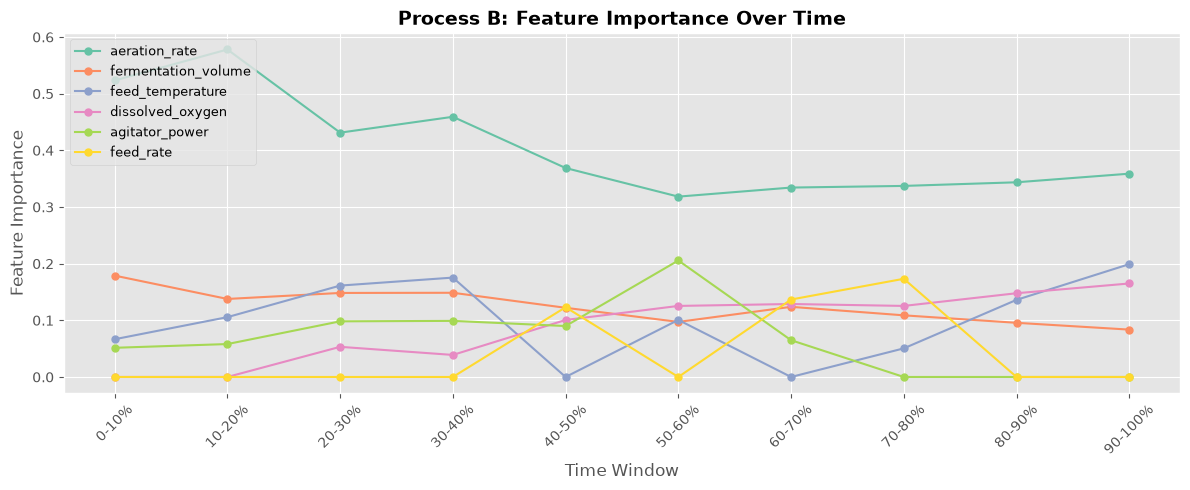


→ aeration_rate dominates EVERY time window (appears in all 10)
→ fermentation_volume is second most important
→ dissolved_oxygen matters in later windows (60-100%)
→ For augmentation focus: aeration_rate, fermentation_volume, dissolved_oxygen, biomass_concentration


In [12]:
# Visualize top features over time
top_features = [f for f, _ in appearance_count.most_common(6)]

fig, ax = plt.subplots(figsize=(12, 5))
windows = list(fi_b.keys())

for feat in top_features:
    values = [fi_b[w].get(feat, 0) for w in windows]
    ax.plot(windows, values, '-o', label=feat, markersize=5, linewidth=1.5)

ax.set_title('Process B: Feature Importance Over Time', fontsize=14, fontweight='bold')
ax.set_xlabel('Time Window'); ax.set_ylabel('Feature Importance')
ax.legend(fontsize=9, loc='upper left')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Key takeaway
print('\n→ aeration_rate dominates EVERY time window (appears in all 10)')
print('→ fermentation_volume is second most important')
print('→ dissolved_oxygen matters in later windows (60-100%)')
print('→ For augmentation focus: aeration_rate, fermentation_volume, dissolved_oxygen, biomass_concentration')